# EDA for Runs with Metrics

In [2]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision/stats/obso
/Users/svasquez/driblab/dl-vision


In [3]:
import json
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np

# Load Data

In [4]:
runs_path = f"stats/obso/datasets/test_filtered_runs.jsonl"


# Load the JSONL file
runs = []
with open(runs_path, 'r') as f:
    for line in f:
        runs.append(json.loads(line))


print(runs[0])
print(f"Run Length: {len(runs)}")

{'match_id': 622090, 'run_id': '622090_12', 'team_id': 4273, 'player_id': 193811, 'ball_carrier_id_start': 1530469, 'ball_carrier_id_end': 1329724, 'start_frame': 2162, 'end_frame': 2186, 'start_timestamp': 215.74, 'end_timestamp': 218.14, 'period': 1, 'runner_info': {'start_position': {'x': 85.21, 'y': 34.86}, 'positions': [{'x': 85.21, 'y': 34.86, 'frame': 2162, 'period': 1}], 'metrics': {'xR_start': 0.4490000009536743, 'xR_end': 0.5879999995231628, 'PC_start': 0.912, 'PC_end': 0.909, 'xG_start': 0.154, 'xG_end': 0.217, 'OBSO_start': None, 'OBSO_end': None}, 'end_position': {'x': 95.62, 'y': 42.24}}, 'possession': {'start_team': '4273', 'end_team': '4273'}, 'off_ball_teammates': [{'player_id': 1166785, 'start_position': {'x': 58.65, 'y': 37.12}, 'end_position': {'x': 70.12, 'y': 33.48}, 'metrics': {'xR_start': 0.34200000762939453, 'xR_end': 0.27300000190734863, 'PC_start': 0.224, 'PC_end': 0.785, 'xG_start': 0.109, 'xG_end': 0.123, 'OBSO_start': None, 'OBSO_end': None}}, {'player_id'

### Load t_player and t_team dfs 

In [5]:
t_player_data = pd.read_csv("/Users/svasquez/AWS_PC/t_player_top5_leagues.csv")
t_team_data = pd.read_csv("/Users/svasquez/AWS_PC/t_team_data.csv")


## Get unique match ids

In [6]:
match_ids = set()

for run in runs:
    match_ids.add(run['match_id'])

print(match_ids)

print(len(match_ids))



{622090, 622092, 622093, 622094, 622096, 622098, 622100, 622101, 622102, 622104, 622106, 622107, 622109, 622112, 622117, 622118, 622121, 622122, 622123, 622124, 622125, 622126, 622128, 622129, 622130, 622133, 622135, 622136, 622139, 622142, 622144, 622146, 622148, 622149, 622150, 622151, 622152, 622153, 622154, 622155, 622156, 622157, 622158, 622159, 622160, 622161, 622162, 622163, 622164, 622165, 622166, 622177, 622178, 622180, 622181, 622182, 622183, 622184, 622185, 622186, 622187, 622188, 622189, 622190, 622191, 622192, 622193, 622194, 622195, 622196, 622197, 622198, 622199, 622202, 622204, 622205, 622207, 622208, 622209, 622211, 622212, 622214, 622216, 622217, 622218, 622220, 622221, 622222, 622223, 622224, 622225, 622226, 622227, 622228, 622229, 622230, 622231, 622233, 622234, 622235, 622236, 622237, 622238, 622239, 622240, 622241, 622242, 622243, 622244, 622245, 622246, 622247, 622248, 622249, 622250, 622251, 622252, 622253, 622254, 622255, 622258, 622259, 622260, 622261, 622263,

## Get distribution of runs by period

len(periods) 13169


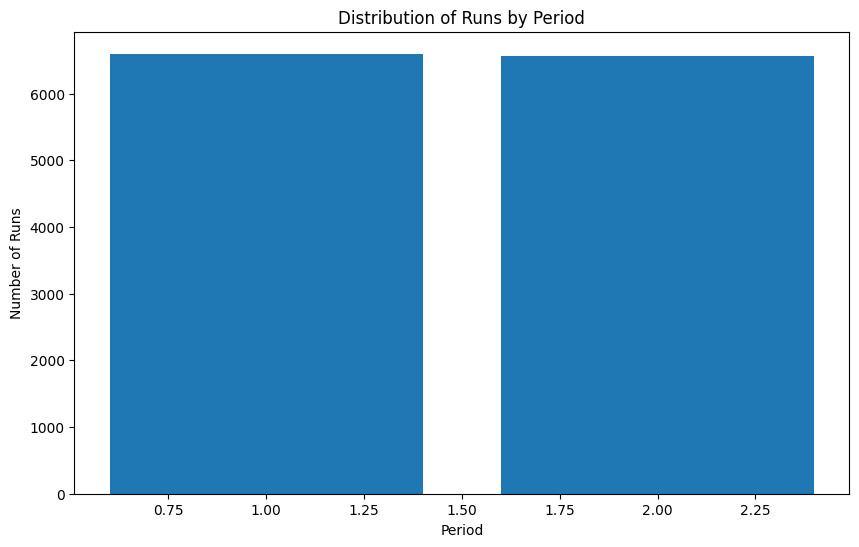

In [7]:
periods = []



for run in runs:
    period = run['period']

    periods.append(period)

print(f"len(periods) {len(periods)}")

# Count frequency of each period
period_counts = pd.Series(periods).value_counts()



# Plot period distribution
plt.figure(figsize=(10,6))
plt.bar(period_counts.index, period_counts.values)
plt.title('Distribution of Runs by Period')
plt.xlabel('Period')
plt.ylabel('Number of Runs')
plt.show()

# Runner EDA

In [8]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Flatten into a pandas DataFrame
def extract_run_info(run):
    runner = run['runner_info']
    start_x, start_y = runner['start_position']['x'], runner['start_position']['y']
    end_x, end_y = runner['end_position']['x'], runner['end_position']['y']
    dx = end_x - start_x
    dy = end_y - start_y
    distance = (dx**2 + dy**2)**0.5
    duration = run['end_timestamp'] - run['start_timestamp']
    speed = distance / duration if duration > 0 else 0

    att_goal_x = run['att_goal'][0]
    att_goal_y = run['att_goal'][1]
    

    


    return {
        "match_id": run["match_id"],
        "run_id": run["run_id"],
        "team_id": run["team_id"],
        "player_id": run["player_id"],
        "start_frame": run["start_frame"],
        "end_frame": run["end_frame"],
        "start_x": start_x,
        "start_y": start_y,
        "end_x": end_x,
        "end_y": end_y,
        "duration": duration,
        "distance": distance,
        "speed": speed,
        "period": run["period"],
        "xR_start": runner["metrics"]["xR_start"],
        "xR_end": runner["metrics"]["xR_end"],
        "PC_start": runner["metrics"]["PC_start"],
        "PC_end": runner["metrics"]["PC_end"],
        "xG_start": runner["metrics"]["xG_start"],
        "xG_end": runner["metrics"]["xG_end"],
        "att_goal_x": att_goal_x,
        "att_goal_y": att_goal_y
    }



df = pd.DataFrame([extract_run_info(r) for r in runs])
# df = pd.DataFrame([extract_run_info(r) for r in filtered_runs])

print(f"LENGTH: {len(df)}")

df.columns



LENGTH: 13169


Index(['match_id', 'run_id', 'team_id', 'player_id', 'start_frame',
       'end_frame', 'start_x', 'start_y', 'end_x', 'end_y', 'duration',
       'distance', 'speed', 'period', 'xR_start', 'xR_end', 'PC_start',
       'PC_end', 'xG_start', 'xG_end', 'att_goal_x', 'att_goal_y'],
      dtype='object')

In [9]:
# remove any runs with negative metrics

print(len(df))
df = df[df['xR_start'] >= 0]
df = df[df['xR_end'] >= 0]
df = df[df['PC_start'] >= 0]
df = df[df['PC_end'] >= 0]
df = df[df['xG_start'] >= 0]
df = df[df['xG_end'] >= 0]


print(len(df))

13169
13168


### Join the t_player_data with the Runner's DF

In [10]:
df = df.merge(t_player_data, on='player_id', how='left')

df.head(10)





,match_id,run_id,team_id_x,player_id,start_frame,end_frame,start_x,start_y,end_x,end_y,...,xG_start,xG_end,att_goal_x,att_goal_y,team_id_y,plyr_name,team_name,season_id,season_name,plyr_position
0,622090,622090_12,4273,193811,2162,2186,85.21,34.86,95.62,42.24,...,0.154,0.217,105,34,4273.0,Aritz Elustondo,Real Sociedad,817531.0,ESP I 2024,DC
1,622090,622090_14,4273,1329663,2216,2240,68.97,4.23,78.12,20.27,...,0.164,0.120,105,34,4273.0,Javier Lopez,Real Sociedad,817531.0,ESP I 2024,DL
2,622090,622090_15,4275,1248194,2412,2430,36.12,64.91,25.17,64.97,...,0.259,0.284,0,34,4275.0,Oscar Valentin,Rayo Vallecano,817531.0,ESP I 2024,DMC
3,622090,622090_44,4273,1329724,5804,5818,76.77,30.92,84.08,31.60,...,0.110,0.116,105,34,4273.0,Jon Pacheco,Real Sociedad,817531.0,ESP I 2024,DC
4,622090,622090_49,4275,1268026,6280,6294,31.21,20.86,20.34,25.86,...,0.098,0.111,0,34,4275.0,Andrei Ratiu,Rayo Vallecano,817531.0,ESP I 2024,DR
5,622090,622090_59,4275,1248194,8568,8584,37.82,4.69,33.30,12.28,...,0.103,0.101,0,34,4275.0,Oscar Valentin,Rayo Vallecano,817531.0,ESP I 2024,DMC
6,622090,622090_120,4273,273054,15316,15383,69.38,11.98,70.16,23.25,...,0.103,0.124,105,34,4273.0,Mikel Oyarzabal,Real Sociedad,817531.0,ESP I 2024,FW
7,622090,622090_121,4273,1530469,15326,15383,64.46,2.90,76.17,33.46,...,0.122,0.135,105,34,4273.0,Beñat Turrientes,Real Sociedad,817531.0,ESP I 2024,DMC
8,622090,622090_122,4273,1329663,15316,15383,72.08,0.49,79.60,15.59,...,0.135,0.141,105,34,4273.0,Javier Lopez,Real Sociedad,817531.0,ESP I 2024,DL
9,622090,622090_162,4275,81306,19640,19658,45.52,41.70,28.51,61.89,...,0.104,0.274,0,34,4275.0,Adrian Embarba,Rayo Vallecano,817531.0,ESP I 2024,AMR


## Plot all the runs

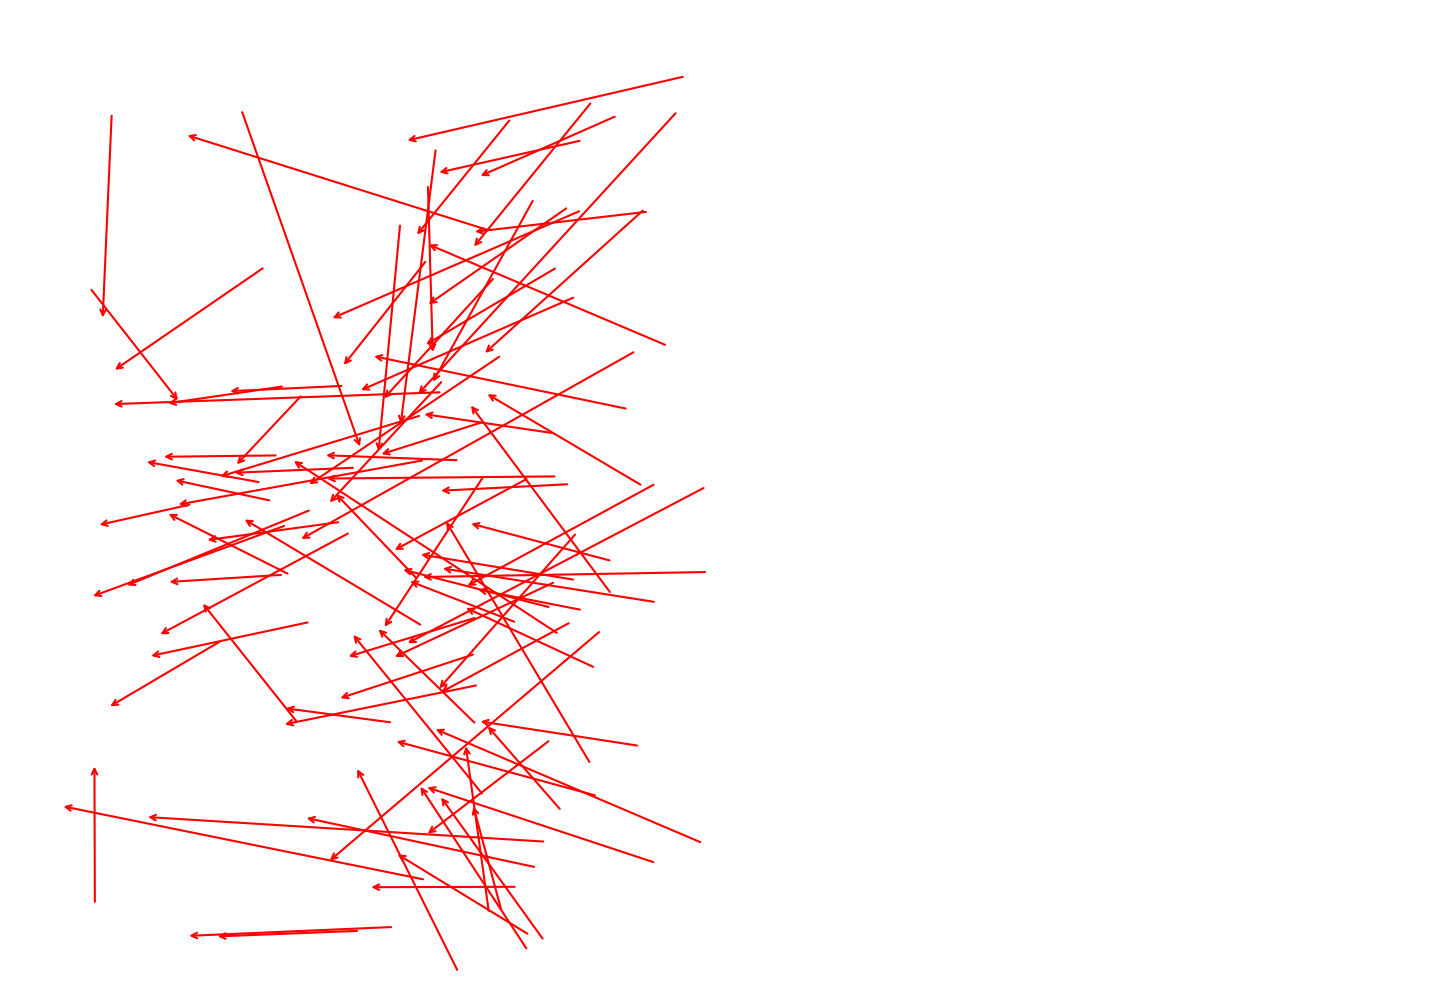

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd

def draw_pitch(ax):
    # Standard 105x68 green pitch with white lines
    ax.set_facecolor('#228B22')  # green
    ax.add_patch(patches.Rectangle((0, 0), 105, 68, linewidth=2, edgecolor='white', facecolor='none'))
    ax.set_xlim(0, 105)
    ax.set_ylim(0, 68)
    ax.set_aspect('equal')
    ax.invert_yaxis()
    ax.axis('off')

def plot_all_runs(df):
    fig, ax = plt.subplots(figsize=(16, 10))
    draw_pitch(ax)

    for _, row in df.iterrows():
        start_x, start_y = row['start_x'], row['start_y']
        end_x, end_y = row['end_x'], row['end_y']

        # Get attack goal
        att_goal_x = row['att_goal_x']
        att_goal_y = row['att_goal_y']

        # print(att_goal_x, att_goal_y)

        if att_goal_x == 105:
            start_x, start_y = 105 - start_x, 68 - start_y
            end_x, end_y = 105 - end_x, 68 - end_y


        ax.annotate("",
                    xy=(end_x, end_y), xytext=(start_x, start_y),
                    arrowprops=dict(arrowstyle="->", color='red', lw=1.5),
                    alpha=0.1)

    ax.set_title("All Detected Runs", fontsize=16, color="white", pad=20)
    fig.patch.set_facecolor('white')  
    plt.tight_layout()
    plt.show()


mini_df = df.sample(n=100, random_state=42)


plot_all_runs(mini_df)


### Get Players with Most Runs

In [12]:


# Group by 'player_id' and count runs
run_counts = df.groupby('player_id')['run_id'].count().reset_index(name='run_count')

# Sort by run count
run_counts = run_counts.sort_values(by='run_count', ascending=False)

# Merge with player data
run_counts = run_counts.merge(t_player_data, on='player_id', how='left')

run_counts.head(10)


,player_id,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
0,1216616,161,4279.0,Raphinha,FC Barcelona,817531.0,ESP I 2024,AML
1,191594,123,4270.0,Inaki Williams,Athletic Club,817531.0,ESP I 2024,AMR
2,1155227,113,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
3,1158830,104,4270.0,Alex Berenguer,Athletic Club,817531.0,ESP I 2024,AMC
4,69936,101,4279.0,Robert Lewandowski,FC Barcelona,817531.0,ESP I 2024,FW
5,20,101,1.0,Antoine Griezmann,Atletico Madrid,817531.0,ESP I 2024,FW
6,1533082,100,4270.0,Nico Williams,Athletic Club,817531.0,ESP I 2024,AML
7,1155702,97,20079.0,Vedat Muriqi,RCD Mallorca,817531.0,ESP I 2024,FW
8,1171076,96,2.0,Hugo Duro,Valencia,817531.0,ESP I 2024,FW
9,1242412,88,1.0,Julian Alvarez,Atletico Madrid,817531.0,ESP I 2024,FW


### Distribution of Runs by players

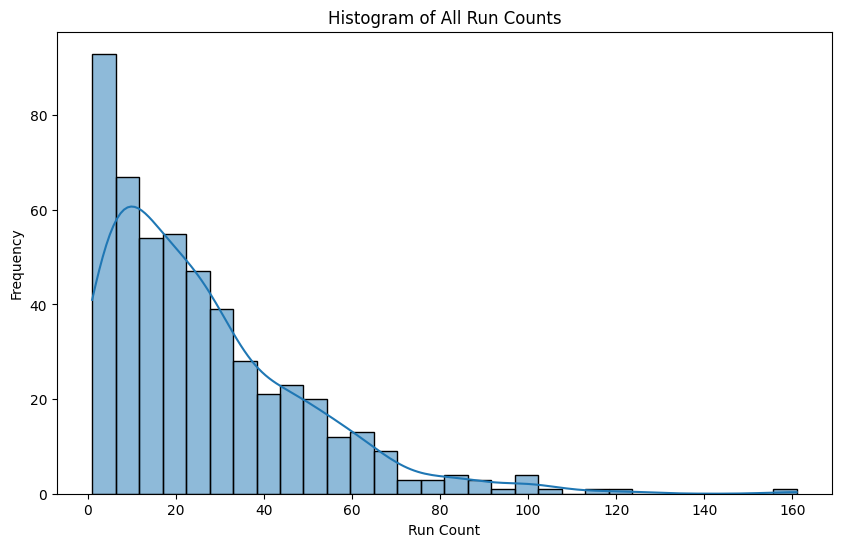

In [13]:
# Create a histogram of all run counts
plt.figure(figsize=(10, 6))
sns.histplot(run_counts['run_count'], bins=30, kde=True)
plt.title("Histogram of All Run Counts")
plt.xlabel("Run Count")
plt.ylabel("Frequency")
plt.show()


### Calculate OBSO added by runner

In [14]:
np.log1p(3)

1.3862943611198906

log(1 + (xR * PC * xG))

In [15]:
import numpy as np

def calc_OBSO(xR, PC, xG):
    return np.log1p(xR * PC * xG)  #

In [16]:
# Calculate total changes for each metric
df["xR_added_runner"] = df["xR_end"] - df["xR_start"]
df["PC_added_runner"] = df["PC_end"] - df["PC_start"] 
df["xG_added_runner"] = df["xG_end"] - df["xG_start"]
df['OBSO_start'] = calc_OBSO(df['xR_start'], df['PC_start'], df['xG_start'])
df['OBSO_end'] = calc_OBSO(df['xR_end'], df['PC_end'], df['xG_end'])
df['OBSO_added'] = df['OBSO_end'] - df['OBSO_start']

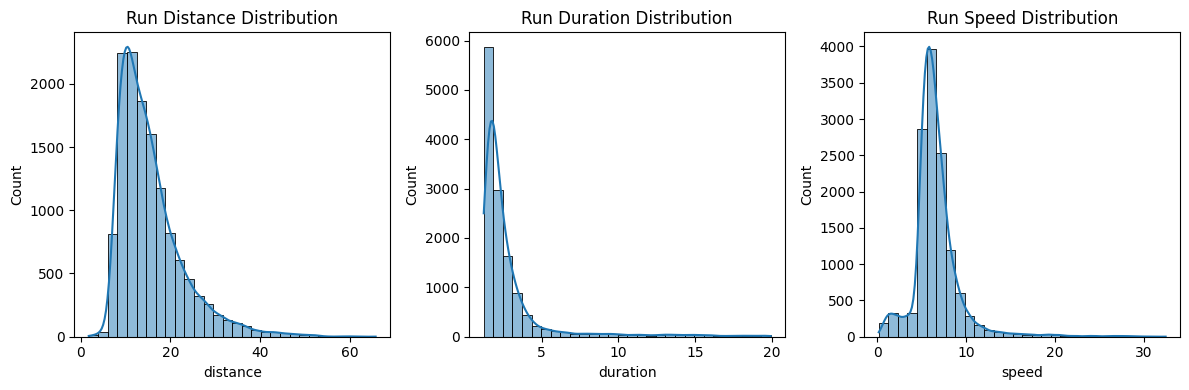

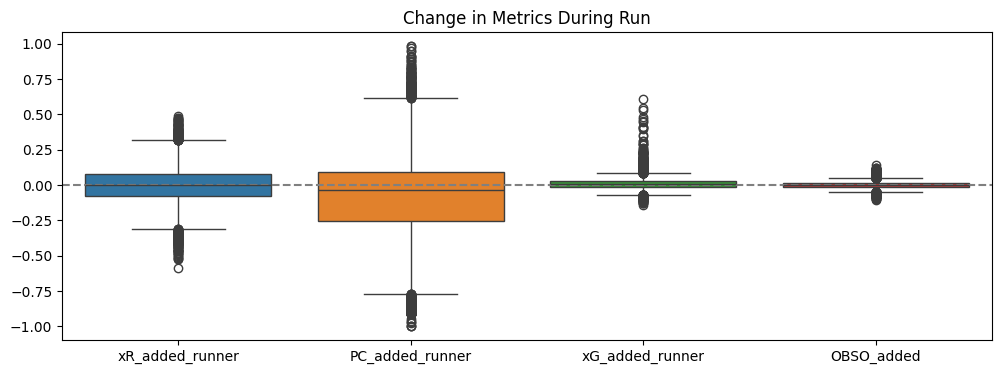

In [17]:

# --- DISTRIBUTIONS ---
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
sns.histplot(df["distance"], bins=30, kde=True)
plt.title("Run Distance Distribution")

plt.subplot(1, 3, 2)
sns.histplot(df["duration"], bins=30, kde=True)
plt.title("Run Duration Distribution")

plt.subplot(1, 3, 3)
sns.histplot(df["speed"], bins=30, kde=True)
plt.title("Run Speed Distribution")

plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 4))
sns.boxplot(data=df[["xR_added_runner", "PC_added_runner", "xG_added_runner", "OBSO_added"]])
plt.title("Change in Metrics During Run")
plt.axhline(0, color="gray", linestyle="--")
plt.show()


# # Optional: save for manual analysis
# df.to_csv("run_eda_summary.csv", index=False)


## Get the top run with runner's change in xG, xR and PC

In [18]:
mean_xR = df['xR_added_runner'].mean()
mean_PC = df['PC_added_runner'].mean()
mean_xG = df['xG_added_runner'].mean()
OBSO_mean = df['OBSO_added'].mean()

print(f"Mean xR: {mean_xR}")
print(f"Mean PC: {mean_PC}")
print(f"Mean xG: {mean_xG}")
print(f"Mean OBSO: {OBSO_mean}")

Mean xR: -0.00024043098499462062
Mean PC: -0.06926291008505467
Mean xG: 0.010238229040097207
Mean OBSO: -0.0005653339638186225


In [19]:
print(df[['xR_start', 'PC_start', 'xG_start', 'xR_end', 'PC_end', 'xG_end']].min())


xR_start    0.118
PC_start    0.000
xG_start    0.030
xR_end      0.114
PC_end      0.000
xG_end      0.030
dtype: float64


## Show distribution for xR, PC, xG and OBSO

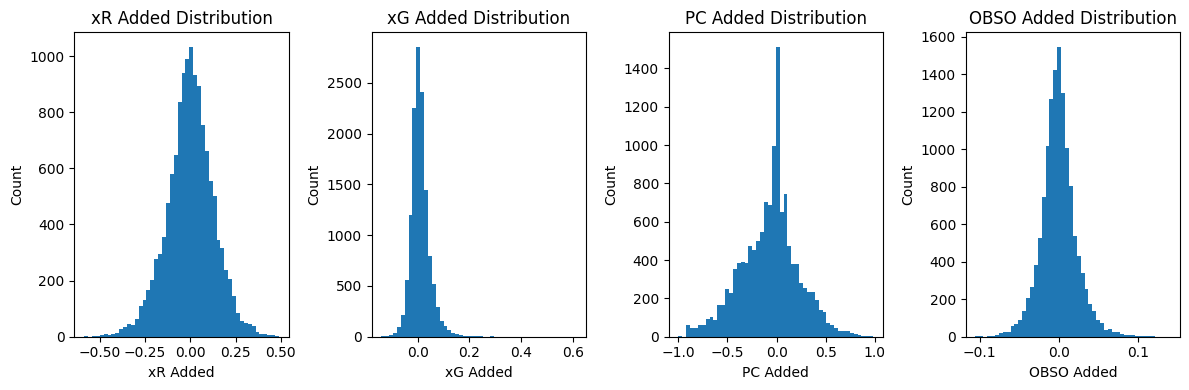

In [20]:
# Create histograms for each metric
plt.figure(figsize=(12, 4))

plt.subplot(141)
plt.hist(df['xR_added_runner'], bins=50)
plt.title('xR Added Distribution')
plt.xlabel('xR Added')
plt.ylabel('Count')

plt.subplot(142)
plt.hist(df['xG_added_runner'], bins=50)
plt.title('xG Added Distribution') 
plt.xlabel('xG Added')
plt.ylabel('Count')

plt.subplot(143)
plt.hist(df['PC_added_runner'], bins=50)
plt.title('PC Added Distribution')
plt.xlabel('PC Added')
plt.ylabel('Count')

plt.subplot(144)
plt.hist(df['OBSO_added'], bins=50)
plt.title('OBSO Added Distribution')
plt.xlabel('OBSO Added')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


## Test Correlation between xR and PC

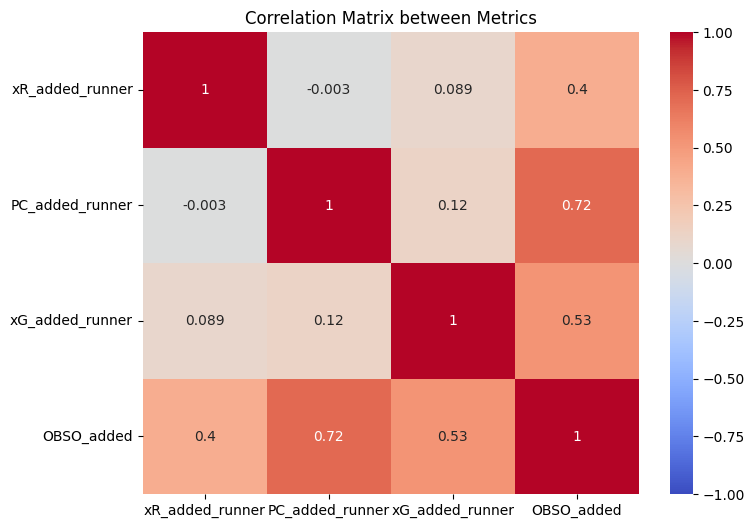

In [21]:
# Calculate correlations between metrics
corr_xR_PC = df['xR_start'].corr(df['PC_start'])
corr_xR_xG = df['xR_start'].corr(df['xG_start']) 
corr_PC_xG = df['PC_start'].corr(df['xG_start'])
corr_OBSO_xR = df['OBSO_start'].corr(df['xR_start'])
corr_OBSO_PC = df['OBSO_start'].corr(df['PC_start'])
corr_OBSO_xG = df['OBSO_start'].corr(df['xG_start'])

# Create correlation matrix plot
plt.figure(figsize=(8, 6))
corr_matrix = df[['xR_added_runner', 'PC_added_runner', 'xG_added_runner', 'OBSO_added']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix between Metrics")
plt.show()



# Top run with more OBSO

In [22]:
df.columns

Index(['match_id', 'run_id', 'team_id_x', 'player_id', 'start_frame',
       'end_frame', 'start_x', 'start_y', 'end_x', 'end_y', 'duration',
       'distance', 'speed', 'period', 'xR_start', 'xR_end', 'PC_start',
       'PC_end', 'xG_start', 'xG_end', 'att_goal_x', 'att_goal_y', 'team_id_y',
       'plyr_name', 'team_name', 'season_id', 'season_name', 'plyr_position',
       'xR_added_runner', 'PC_added_runner', 'xG_added_runner', 'OBSO_start',
       'OBSO_end', 'OBSO_added'],
      dtype='object')

In [23]:
top_runs_df =df.nlargest(10, "OBSO_added")

# Keep only relevant columns
top_runs_df = top_runs_df[["match_id", "run_id", 'plyr_name',"team_name", "xR_added_runner", "PC_added_runner", "xG_added_runner", "OBSO_added"]]

top_runs_df





,match_id,run_id,plyr_name,team_name,xR_added_runner,PC_added_runner,xG_added_runner,OBSO_added
3159,622186,622186_286,Axel Witsel,Atletico Madrid,-0.019,0.716,0.203,0.140505
11157,622338,622338_391,Sergi Darder,RCD Mallorca,-0.014,0.411,0.309,0.120557
2720,622177,622177_192,Brian Olivan,Espanyol,0.021,0.288,0.246,0.120103
2760,622178,622178_232,Cristhian Mosquera,Valencia,0.174,0.810,0.127,0.119149
9603,622311,622311_346,Kylian Mbappe,Real Madrid,-0.050,0.326,0.347,0.116008
5288,622234,622234_233,Nahuel Tenaglia,Deportivo Alaves,0.121,0.294,0.187,0.114549
6600,622254,622254_280,Jude Bellingham,Real Madrid,-0.019,-0.128,0.528,0.114153
397,622104,622104_274,Diego Rico,Getafe,0.194,0.571,0.108,0.111920
1841,622151,622151_347,Jorge Saenz,Leganes,-0.030,0.466,0.224,0.111330
6051,622246,622246_99,Santi Comesana,Villarreal,0.027,0.146,0.180,0.110677


# Team Wide Runs EDA

In [87]:
runs[0]

{'match_id': 622090,
 'run_id': '622090_12',
 'team_id': 4273,
 'player_id': 193811,
 'ball_carrier_id_start': 1530469,
 'ball_carrier_id_end': 1329724,
 'start_frame': 2162,
 'end_frame': 2186,
 'start_timestamp': 215.74,
 'end_timestamp': 218.14,
 'period': 1,
 'runner_info': {'start_position': {'x': 85.21, 'y': 34.86},
  'positions': [{'x': 85.21, 'y': 34.86, 'frame': 2162, 'period': 1}],
  'metrics': {'xR_start': 0.4490000009536743,
   'xR_end': 0.5879999995231628,
   'PC_start': 0.912,
   'PC_end': 0.909,
   'xG_start': 0.154,
   'xG_end': 0.217,
   'OBSO_start': None,
   'OBSO_end': None},
  'end_position': {'x': 95.62, 'y': 42.24}},
 'possession': {'start_team': '4273', 'end_team': '4273'},
 'off_ball_teammates': [{'player_id': 1166785,
   'start_position': {'x': 58.65, 'y': 37.12},
   'end_position': {'x': 70.12, 'y': 33.48},
   'metrics': {'xR_start': 0.34200000762939453,
    'xR_end': 0.27300000190734863,
    'PC_start': 0.224,
    'PC_end': 0.785,
    'xG_start': 0.109,
    

In [91]:







# Create a DataFrame to hold team-wide deltas
rows = []

for run in runs:
    run_id = run['run_id']
    match_id = run['match_id']
    period = run['period']
    team_id = run['team_id']

    # Get run start and end
    run_start = run['runner_info']['start_position']['x'] , run['runner_info']['start_position']['y']
    run_end = run['runner_info']['end_position']['x'] , run['runner_info']['end_position']['y']

    # Get distance

    dx = run_end[0] - run_start[0]
    dy = run_end[1] - run_start[1]
    distance = (dx**2 + dy**2)**0.5

    

    if distance < 10: continue

    # Runner data

    runner_id = run['player_id']

    # Runner metrics
    runner_metrics = run['runner_info']['metrics']
    xR_start = runner_metrics['xR_start']
    xR_end = runner_metrics['xR_end']
    PC_start = runner_metrics['PC_start']
    PC_end = runner_metrics['PC_end']
    xG_start = runner_metrics['xG_start']
    xG_end = runner_metrics['xG_end']

    # Runners OBSO
    OBSO_start = calc_OBSO(xR_start, PC_start, xG_start)
    OBSO_end = calc_OBSO(xR_end, PC_end, xG_end)
    OBSO_delta = OBSO_end - OBSO_start


    # get ball carrier

    ball_carrier_id_start = run['ball_carrier_id_start']
    ball_carrier_id_end = run['ball_carrier_id_end']



    sum_OBSO = 0  + OBSO_delta

    sum_xR_delta = 0 + (xR_end - xR_start)
    sum_PC_delta = 0 + (PC_end - PC_start)
    sum_xG_delta = 0 + (xG_end - xG_start)

    for teammate in run.get('off_ball_teammates', []):

        metrics = teammate.get('metrics', {})

        # if teammate is the ball carrier
        if teammate['player_id'] == ball_carrier_id_start:

            xR_start = 0
            PC_start = 0
            xG_start = 0

        else:
            # Get start metrics
            xR_start = metrics.get('xR_start', 0) or 0
            PC_start = metrics.get('PC_start', 0) or 0
            xG_start = metrics.get('xG_start', 0) or 0

        if teammate['player_id'] == ball_carrier_id_end:
            xR_end = 0
            PC_end = 0
            xG_end = 0

        else:
            # Get end metrics
            xR_end = metrics.get('xR_end', 0) or 0
            PC_end = metrics.get('PC_end', 0) or 0
            xG_end = metrics.get('xG_end', 0) or 0

        # xR Added team
        xR_added_team = xR_end - xR_start
        sum_xR_delta += xR_added_team

        PC_added_team = PC_end - PC_start
        sum_PC_delta += PC_added_team

        xG_added_team = xG_end - xG_start
        sum_xG_delta += xG_added_team

        OBSO_start = calc_OBSO(xR_start, PC_start, xG_start)
        OBSO_end = calc_OBSO(xR_end, PC_end, xG_end)
        # OBSO_delta = OBSO_end - OBSO_start
        OBSO_delta = OBSO_start -  OBSO_end 

        sum_OBSO += OBSO_delta



    rows.append({
        "match_id": match_id,
        "run_id": run_id,
        'player_id': runner_id,
        "team_id": team_id,
        "period": period,
        "xR_added_team": sum_xR_delta,
        "PC_added_team": sum_PC_delta,
        "xG_added_team": sum_xG_delta,
        "OBSO_added_team": sum_OBSO
    })

team_wide_df = pd.DataFrame(rows)

# Merge with t_player_data
team_wide_df = team_wide_df.merge(t_player_data, on='player_id', how='left')

team_wide_df

,match_id,run_id,player_id,team_id_x,period,xR_added_team,PC_added_team,xG_added_team,OBSO_added_team,team_id_y,plyr_name,team_name,season_id,season_name,plyr_position
0,622090,622090_12,193811,4273,1,-1.622,0.769,0.105,0.130985,4273.0,Aritz Elustondo,Real Sociedad,817531.0,ESP I 2024,DC
1,622090,622090_14,1329663,4273,1,-0.132,2.469,-0.084,-0.010440,4273.0,Javier Lopez,Real Sociedad,817531.0,ESP I 2024,DL
2,622090,622090_15,1248194,4275,1,-0.256,-0.302,0.098,0.002649,4275.0,Oscar Valentin,Rayo Vallecano,817531.0,ESP I 2024,DMC
3,622090,622090_49,1268026,4275,1,-0.191,0.449,-0.012,0.003985,4275.0,Andrei Ratiu,Rayo Vallecano,817531.0,ESP I 2024,DR
4,622090,622090_120,273054,4273,1,-0.739,0.835,-0.051,0.059628,4273.0,Mikel Oyarzabal,Real Sociedad,817531.0,ESP I 2024,FW
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10400,638268,638268_361,1526425,4266,2,-0.091,1.903,0.325,-0.130655,NaN,NaN,NaN,NaN,NaN,NaN
10401,638268,638268_368,1293836,4266,2,0.317,0.634,-0.023,-0.001958,4266.0,Johnny Cardoso,Real Betis,817531.0,ESP I 2024,DMC
10402,638268,638268_369,270420,4266,2,0.431,-0.788,0.043,0.072767,4266.0,Pablo Fornals,Real Betis,817531.0,ESP I 2024,MR
10403,638268,638268_378,270420,4266,2,-0.055,-0.382,-0.015,-0.050636,4266.0,Pablo Fornals,Real Betis,817531.0,ESP I 2024,MR


In [90]:
len(team_wide_df)

0

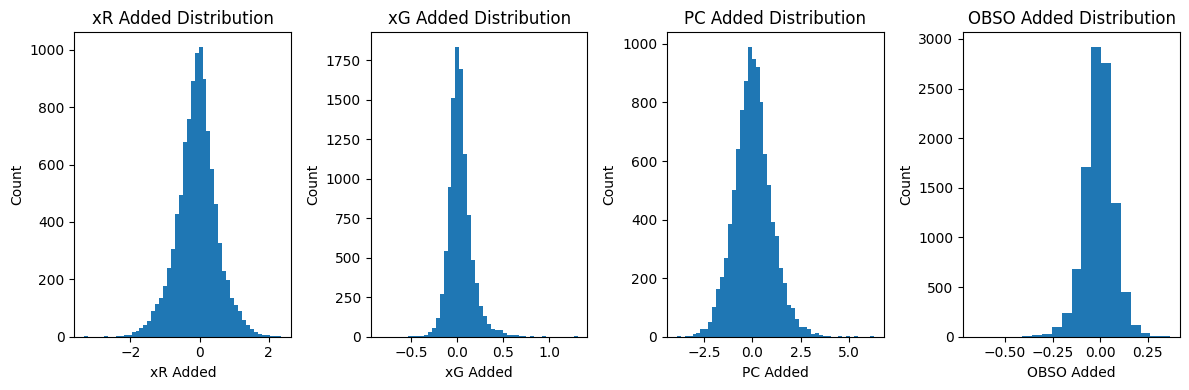

In [92]:
# Create histograms for each metric
plt.figure(figsize=(12, 4))

plt.subplot(141)
plt.hist(team_wide_df['xR_added_team'], bins=50)
plt.title('xR Added Distribution')
plt.xlabel('xR Added')
plt.ylabel('Count')

plt.subplot(142)
plt.hist(team_wide_df['xG_added_team'], bins=50)
plt.title('xG Added Distribution') 
plt.xlabel('xG Added')
plt.ylabel('Count')

plt.subplot(143)
plt.hist(team_wide_df['PC_added_team'], bins=50)
plt.title('PC Added Distribution')
plt.xlabel('PC Added')
plt.ylabel('Count')

plt.subplot(144)
plt.hist(team_wide_df['OBSO_added_team'], bins=20)
plt.title('OBSO Added Distribution')
plt.xlabel('OBSO Added')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


In [93]:

print("\n📊 Basic stats per metric:")
print(team_wide_df[["xR_added_team", "PC_added_team", "xG_added_team", "OBSO_added_team"]].describe())




📊 Basic stats per metric:
       xR_added_team  PC_added_team  xG_added_team  OBSO_added_team
count   10405.000000   10405.000000   10405.000000     10405.000000
mean       -0.073036       0.029502       0.033392        -0.005527
std         0.573803       0.972352       0.132322         0.077292
min        -3.329000      -3.917000      -0.831000        -0.667787
25%        -0.405000      -0.590000      -0.043000        -0.050637
50%        -0.058000      -0.004000       0.020000        -0.002916
75%         0.263000       0.610000       0.093000         0.042578
max         2.364000       6.298000       1.305000         0.367252


In [94]:
print("\n📈 Top 5 runs by team xR added:")
top_runs = team_wide_df.sort_values(by="OBSO_added_team", ascending=False).head()
top_runs




📈 Top 5 runs by team xR added:


,match_id,run_id,player_id,team_id_x,period,xR_added_team,PC_added_team,xG_added_team,OBSO_added_team,team_id_y,plyr_name,team_name,season_id,season_name,plyr_position
9703,622359,622359_46,1237127,4272,1,0.091,-3.917,-0.233,0.367252,4272.0,Diego Conde,Villarreal,817531.0,ESP I 2024,GK
6237,622280,622280_918,89567,20079,2,-1.112,-2.562,-0.186,0.350767,20079.0,Omar Mascarell,RCD Mallorca,817531.0,ESP I 2024,MC
4382,622239,622239_564,189024,4275,2,-0.841,-2.755,-0.138,0.332229,4275.0,Unai Lopez,Rayo Vallecano,817531.0,ESP I 2024,DMC
588,622124,622124_166,1254156,4273,1,-3.329,-0.737,-0.181,0.304528,4273.0,Ander Barrenetxea,Real Sociedad,817531.0,ESP I 2024,ML
6238,622280,622280_919,1158747,20079,2,-0.783,-1.475,-0.161,0.293226,20079.0,Takuma Asano,RCD Mallorca,817531.0,ESP I 2024,MR


## Get SUmmed OBSO for the best 20 runs of each player 

In [95]:
team_wide_df

import pandas as pd

# Assuming your DataFrame is named df

# Step 1: Sort by player_id and OBSO_added_team descending
team_wide_df = team_wide_df.sort_values(by=["player_id", "OBSO_added_team"], ascending=[True, False])

# Step 2: Take top 20 runs per player
top20_per_player = team_wide_df.groupby("player_id").head(20)



# Merge with run counts
top20_per_player = top20_per_player.merge(run_counts, on='player_id', how='left')

# Keep only players with at least 20 runs
top20_per_player = top20_per_player[top20_per_player['run_count'] >= 20]

top20_per_player.columns


# Step 3: Sum OBSO_added_team for each player
obso_sums = top20_per_player.groupby(["player_id", "plyr_name_x", "team_name_x"])[
    "OBSO_added_team"
].sum().reset_index().rename(columns={"OBSO_added_team": "top20_OBSO_sum"})

# (Optional) Sort by highest summed OBSO
obso_sums = obso_sums.sort_values(by="top20_OBSO_sum", ascending=False)

# Display result
obso_sums.head(20)


,player_id,plyr_name_x,team_name_x,top20_OBSO_sum
65,1155227,Kylian Mbappe,Real Madrid,2.060659
5,20,Antoine Griezmann,Atletico Madrid,2.007347
36,163093,Kike Garcia,Deportivo Alaves,1.945723
116,1216616,Raphinha,FC Barcelona,1.938660
47,199339,Javi Munoz,UD Las Palmas,1.909801
83,1158830,Alex Berenguer,Athletic Club,1.888367
262,1776309,Lamine Yamal,FC Barcelona,1.827461
16,80798,Alvaro Garcia,Rayo Vallecano,1.774298
117,1217051,Anuar,Valladolid,1.743023
206,1338378,Óscar Mingueza,Celta de Vigo,1.713290


## Aggregate OBSO added team by Player

In [121]:
agg_OBSO_team = team_wide_df.groupby('player_id')['OBSO_added_team'].sum().reset_index()

agg_OBSO_team = agg_OBSO_team.sort_values(by='OBSO_added_team', ascending=False)

# Merge with run counts
agg_OBSO_team = agg_OBSO_team.merge(run_counts, on='player_id', how='left')


print(f"LENGTH: {len(agg_OBSO_team)}")
# Filter out players with less than 10 runs
agg_OBSO_team = agg_OBSO_team[agg_OBSO_team['run_count'] >= 30]

print(f"LENGTH: {len(agg_OBSO_team)}")

agg_OBSO_team.head(20)


LENGTH: 495
LENGTH: 171


,player_id,OBSO_added_team,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
0,20,1.322400,101,1.0,Antoine Griezmann,Atletico Madrid,817531.0,ESP I 2024,FW
1,1253602,1.230100,35,4269.0,Juanmi Latasa,Valladolid,817531.0,ESP I 2024,FW
2,1534575,1.209013,41,4263.0,Ilaix Moriba,Celta de Vigo,817531.0,ESP I 2024,MC
3,482107,0.936338,33,4270.0,Yuri Berchiche,Athletic Club,817531.0,ESP I 2024,DL
4,1262780,0.902398,58,4264.0,Alex Kral,Espanyol,817531.0,ESP I 2024,MC
5,1776309,0.825582,86,4279.0,Lamine Yamal,FC Barcelona,817531.0,ESP I 2024,AMR
6,1329725,0.820605,45,4267.0,Aimar Oroz,Osasuna,817531.0,ESP I 2024,MC
8,189153,0.692661,47,14350.0,Sandro Ramirez,UD Las Palmas,817531.0,ESP I 2024,AMR
9,1158830,0.680151,104,4270.0,Alex Berenguer,Athletic Club,817531.0,ESP I 2024,AMC
10,1295822,0.638506,30,4263.0,Iker Losada,Celta de Vigo,817531.0,ESP I 2024,FWR


## Get Player Specific OBSO

In [102]:
mbappe_df = team_wide_df[team_wide_df['player_id'] == 1155227]

# Sort by OBSO added team
mbappe_df = mbappe_df.sort_values(by='OBSO_added_team', ascending=False)

# Sum OBSO added team
mbappe_df['OBSO_added_team'].sum()

0.536968943660568

In [103]:
mbappe_df.tail(10)

,match_id,run_id,player_id,team_id_x,period,xR_added_team,PC_added_team,xG_added_team,OBSO_added_team,team_id_y,plyr_name,team_name,season_id,season_name,plyr_position
6102,622278,622278_146,1155227,4265,1,0.111,0.498,0.079,-0.071325,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
9255,622347,622347_100,1155227,4265,1,-0.071,1.426,-0.086,-0.079519,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
2085,622165,622165_269,1155227,4265,2,0.106,0.239,0.085,-0.080658,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
462,622112,622112_263,1155227,4265,2,0.141,-0.194,0.179,-0.081497,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
6073,622278,622278_35,1155227,4265,1,0.896,0.731,0.060,-0.092671,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
2090,622165,622165_293,1155227,4265,2,-0.478,0.751,0.075,-0.096871,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
7287,622300,622300_435,1155227,4265,2,0.853,0.125,0.071,-0.109794,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
3930,622229,622229_354,1155227,4265,2,-0.054,1.128,0.293,-0.163632,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
3181,622209,622209_40,1155227,4265,1,0.875,1.288,0.318,-0.184996,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
6095,622278,622278_118,1155227,4265,1,0.626,1.694,0.188,-0.197414,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW


In [104]:
agg_xG_team = team_wide_df.groupby('player_id')['xG_added_team'].mean().reset_index()

agg_xG_team = agg_xG_team.sort_values(by='xG_added_team', ascending=False)

# Merge with run counts
agg_xG_team = agg_xG_team.merge(run_counts, on='player_id', how='left')


print(f"LENGTH: {len(agg_xG_team)}")
# Filter out players with less than 10 runs
agg_xG_team = agg_xG_team[agg_xG_team['run_count'] >= 30]

print(f"LENGTH: {len(agg_xG_team)}")

agg_xG_team.tail(10)

LENGTH: 495
LENGTH: 171


,player_id,xG_added_team,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
425,482107,-0.005345,33,4270.0,Yuri Berchiche,Athletic Club,817531.0,ESP I 2024,DL
430,1157714,-0.006333,35,4266.0,Giovani Lo Celso,Real Betis,817531.0,ESP I 2024,AMC
435,1759377,-0.008442,58,4272.0,Thierno Barry,Villarreal,817531.0,ESP I 2024,FW
444,1533082,-0.012802,100,4270.0,Nico Williams,Athletic Club,817531.0,ESP I 2024,AML
448,1169460,-0.014791,87,4265.0,Rodrygo,Real Madrid,817531.0,ESP I 2024,MR
449,1313767,-0.015000,68,4266.0,Abde Ezzalzouli,Real Betis,817531.0,ESP I 2024,AML
452,1171131,-0.016978,53,4273.0,Sergio Gomez,Real Sociedad,817531.0,ESP I 2024,ML
460,1163220,-0.024143,79,4265.0,Vinicius Junior,Real Madrid,817531.0,ESP I 2024,FW
473,1169797,-0.032884,60,4279.0,Ferran Torres,FC Barcelona,817531.0,ESP I 2024,FW
480,189153,-0.037455,47,14350.0,Sandro Ramirez,UD Las Palmas,817531.0,ESP I 2024,AMR


## Aggregate OBSO by position

In [105]:
agg_OBSO_position = agg_OBSO_team.groupby('plyr_position')['OBSO_added_team'].sum().reset_index()

agg_OBSO_position = agg_OBSO_position.sort_values(by='OBSO_added_team', ascending=False)
agg_OBSO_position

,plyr_position,OBSO_added_team
11,FWR,0.638506
10,FWL,0.406173
7,DMR,0.404546
13,ML,-0.134912
2,AMR,-0.274228
6,DML,-1.160568
5,DMC,-1.290560
0,AMC,-1.516810
1,AML,-1.889326
14,MR,-2.181255


## Visualize OBSO vs Run Count

    player_id  OBSO_added_team  run_count  team_id          plyr_name  \
0          20         1.322400        101      1.0  Antoine Griezmann   
1     1253602         1.230100         35   4269.0      Juanmi Latasa   
2     1534575         1.209013         41   4263.0       Ilaix Moriba   
3      482107         0.936338         33   4270.0     Yuri Berchiche   
4     1262780         0.902398         58   4264.0          Alex Kral   
5     1776309         0.825582         86   4279.0       Lamine Yamal   
9     1158830         0.680151        104   4270.0     Alex Berenguer   
13    1155227         0.536969        113   4265.0      Kylian Mbappe   
29     198129         0.391445         87   4263.0     Borja Iglesias   
66    1169460         0.229142         87   4265.0            Rodrygo   

          team_name  season_id season_name plyr_position  
0   Atletico Madrid   817531.0  ESP I 2024            FW  
1        Valladolid   817531.0  ESP I 2024            FW  
2     Celta de Vigo

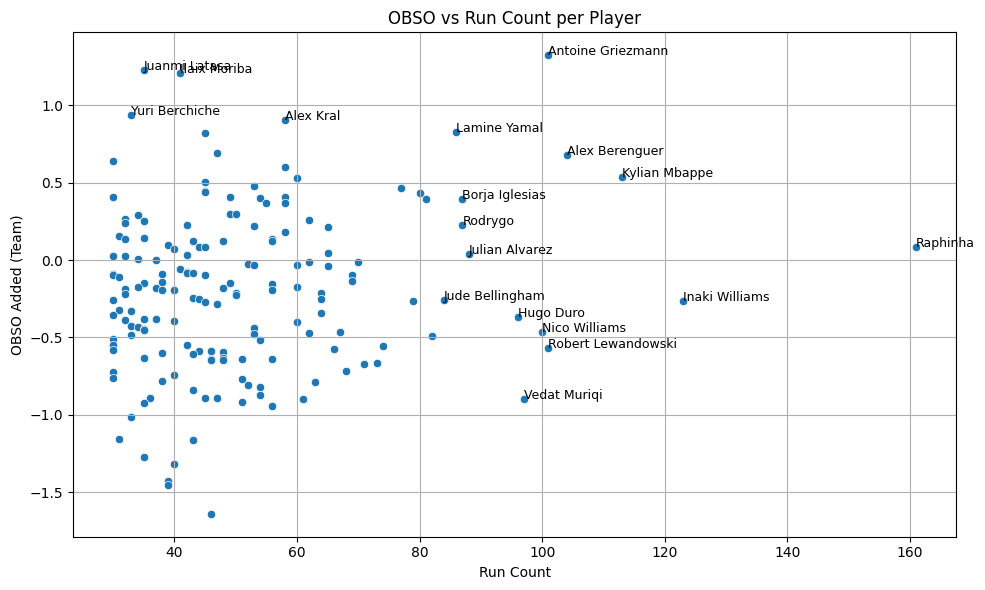

In [109]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=agg_OBSO_team, x='run_count', y='OBSO_added_team')

# Filter players with more than 1 OBSO and more than 100 runs
filtered_players = agg_OBSO_team[(agg_OBSO_team['OBSO_added_team'] > 0.9) | (agg_OBSO_team['run_count'] > 82)]


print(filtered_players.head(10))
# Annotate player names
for i in range(filtered_players.shape[0]):
    plt.text(filtered_players['run_count'].iloc[i], 
             filtered_players['OBSO_added_team'].iloc[i], 
             filtered_players['plyr_name'].iloc[i], 
             fontsize=9)

plt.title('OBSO vs Run Count per Player')
plt.xlabel('Run Count')
plt.ylabel('OBSO Added (Team)')
plt.grid(True)
plt.tight_layout()
plt.show()


## Normalize OBSO

In [31]:
agg_OBSO_team['OBSO_per_run'] = agg_OBSO_team['OBSO_added_team'] / agg_OBSO_team['run_count']
top_eff = agg_OBSO_team.sort_values(by='OBSO_per_run', ascending=False).head(20)

top_eff[['plyr_name', 'team_name', 'run_count', 'OBSO_added_team', 'OBSO_per_run']]


,plyr_name,team_name,run_count,OBSO_added_team,OBSO_per_run
0,Adria Pedrosa,Sevilla,40,2.503859,0.062596
2,Raul Albiol,Villarreal,40,2.322675,0.058067
1,Nayef Aguerd,Real Sociedad,46,2.328253,0.050614
6,Nemanja Gudelj,Sevilla,34,1.656376,0.048717
4,Cristhian Mosquera,Valencia,40,1.876062,0.046902
7,Hugo Sotelo,Celta de Vigo,33,1.478128,0.044792
3,Jose Ángel Carmona,Sevilla,45,1.926124,0.042803
5,Logan Costa,Villarreal,47,1.681852,0.035784
31,Carles Perez,Getafe,30,0.976965,0.032565
32,Andre Almeida,Valencia,30,0.975502,0.032517


## Compare per 90 mins

In [32]:
# OBSO per 90 minutes
agg_OBSO_team['OBSO_per_90'] = agg_OBSO_team['OBSO_added_team'] /  90

top_90 = agg_OBSO_team.sort_values(by='OBSO_per_90', ascending=False).head(20)
print(top_90[['plyr_name', 'OBSO_added_team', 'OBSO_per_90']])


             plyr_name  OBSO_added_team  OBSO_per_90
0        Adria Pedrosa         2.503859     0.027821
1         Nayef Aguerd         2.328253     0.025869
2          Raul Albiol         2.322675     0.025808
3   Jose Ángel Carmona         1.926124     0.021401
4   Cristhian Mosquera         1.876062     0.020845
5          Logan Costa         1.681852     0.018687
6       Nemanja Gudelj         1.656376     0.018404
7          Hugo Sotelo         1.478128     0.016424
8      Florian Lejeune         1.429668     0.015885
9           Álex Baena         1.381553     0.015351
11    Alejandro Catena         1.254606     0.013940
14           Hugo Duro         1.197539     0.013306
15     Sergio Gonzalez         1.186423     0.013182
19      Flavien Boyomo         1.123412     0.012482
22           Loic Bade         1.100172     0.012224
24    Martin Zubimendi         1.072927     0.011921
25      Sergio Camello         1.068036     0.011867
29     Nahuel Tenaglia         0.989092     0.

## Team-level aggregation

In [110]:
# Load t_team_data
t_team_data = pd.read_csv("/Users/svasquez/AWS_PC/t_team_top5_leagues.csv")



In [126]:
team_OBSO = agg_OBSO_team.groupby('team_id').agg({'OBSO_added_team': 'sum', 'team_id': 'count'}).rename(columns={'team_id': 'row_count'}).reset_index()
team_OBSO

# # Merge with t_team_data
team_OBSO = team_OBSO.merge(t_team_data, on='team_id', how='left')

team_OBSO

,team_id,OBSO_added_team,row_count,team_name
0,1.0,-1.520037,12,Atletico Madrid
1,2.0,-1.400857,6,Valencia
2,4263.0,-0.075740,14,Celta de Vigo
3,4264.0,-1.063864,5,Espanyol
4,4265.0,-0.443686,9,Real Madrid
5,4266.0,-1.488191,9,Real Betis
6,4267.0,-1.671483,9,Osasuna
7,4269.0,0.468303,8,Valladolid
8,4270.0,1.320567,7,Athletic Club
9,4272.0,-1.771911,9,Villarreal


/var/folders/50/x46v3vxd4b113nhtgtbw0f2c0000gp/T/ipykernel_10707/504332586.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=team_OBSO, x='OBSO_added_team', y='team_name', palette='viridis')


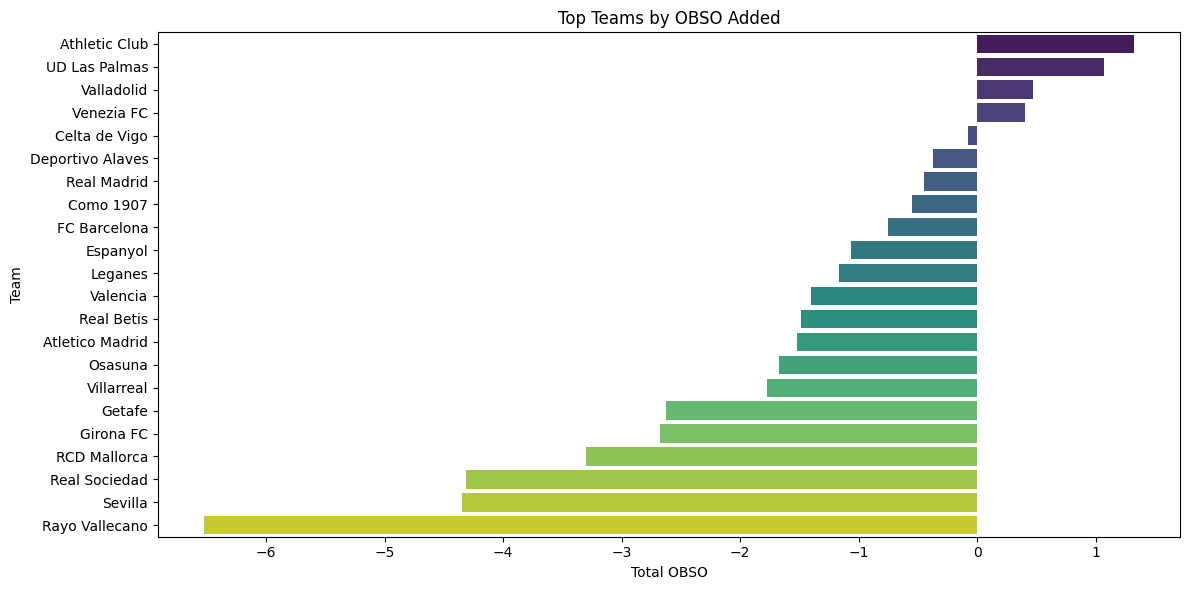

In [127]:

team_OBSO = team_OBSO.sort_values(by='OBSO_added_team', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=team_OBSO, x='OBSO_added_team', y='team_name', palette='viridis')
plt.title('Top Teams by OBSO Added')
plt.xlabel('Total OBSO')
plt.ylabel('Team')
plt.tight_layout()
plt.show()


# Plot Runs

In [36]:
from stats.obso.run_detection.plot_run import PlotRun
match_id = 622593
    
pr = PlotRun(match_id)

pr.load_pitch_control()



ModuleNotFoundError: No module named 'xReceiver'

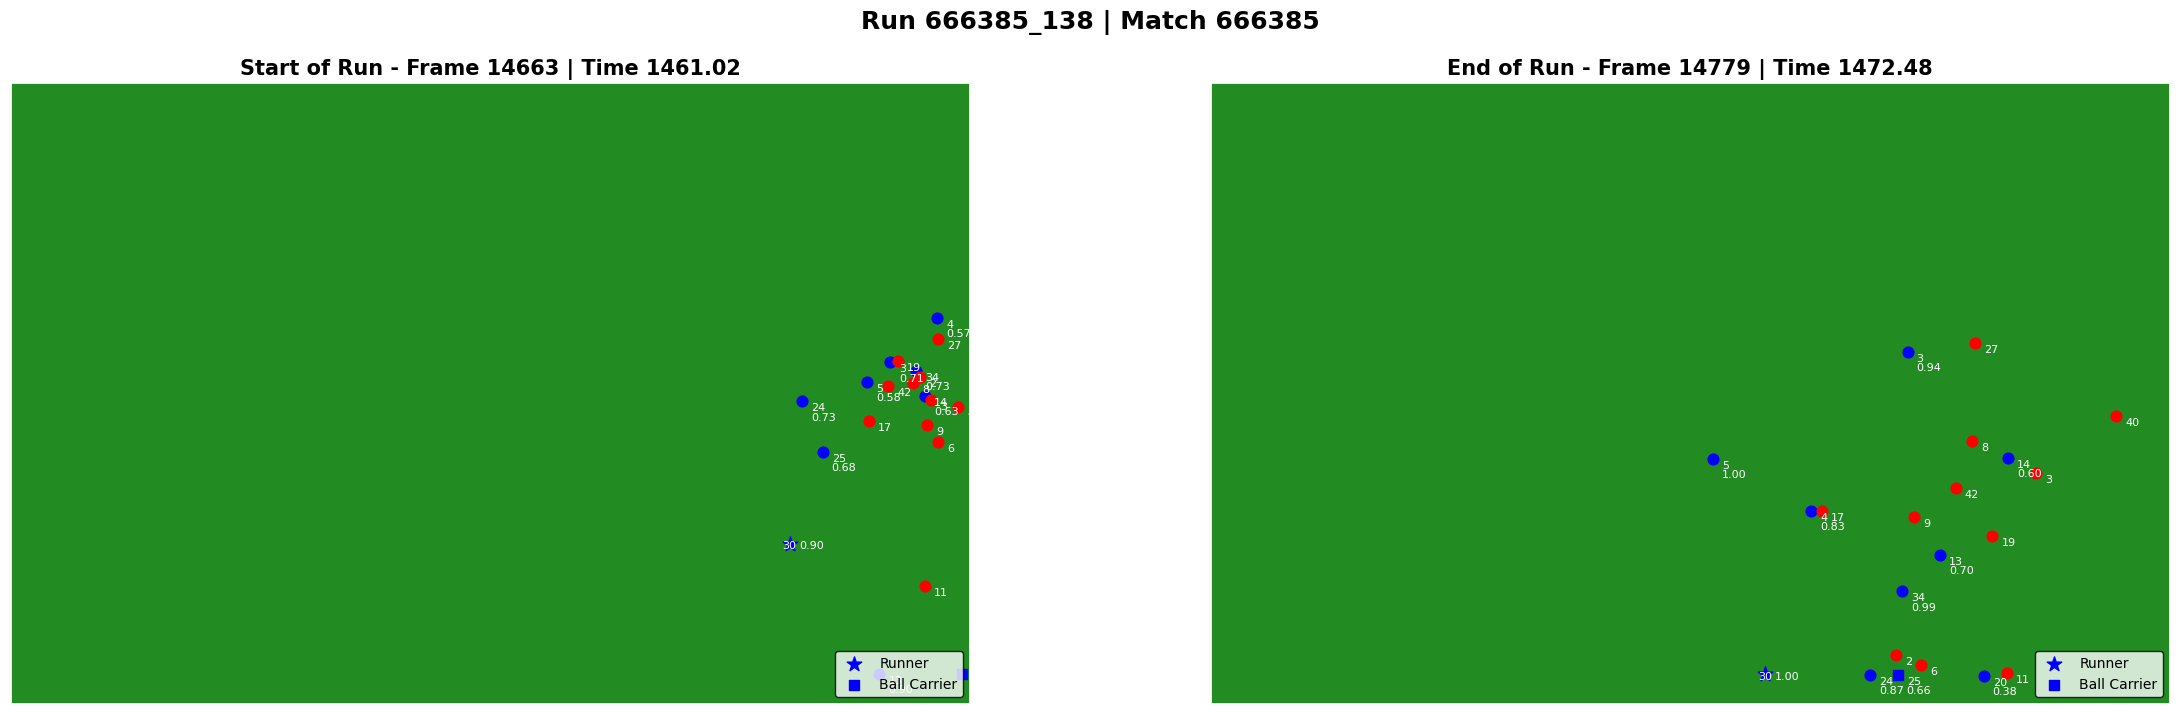

In [35]:


run_id = 138
fig = pr.plot_run(pr.runs[run_id], pr.player_lookup, pc_annotate = True, def_team = True)
plt.show()

# Calculate Raw OBSO

In [38]:
def calc_raw_obso(xR, PC, xG):
    return xR * PC * (xG **1)



team_wide_obso = []
for run in runs:

    team_wide_OBSO_start = 0
    team_wide_OBSO_end = 0

    # Calculate raw OBSO for runner
    runner_OBSO_start = calc_raw_obso(run['runner_info']['metrics']['xR_start'], run['runner_info']['metrics']['PC_start'], run['runner_info']['metrics']['xG_start'])
    runner_OBSO_end = calc_raw_obso(run['runner_info']['metrics']['xR_end'], run['runner_info']['metrics']['PC_end'], run['runner_info']['metrics']['xG_end'])

    team_wide_OBSO_start += runner_OBSO_start
    team_wide_OBSO_end += runner_OBSO_end

    run['runner_info']['metrics']['OBSO_start'] = runner_OBSO_start
    run['runner_info']['metrics']['OBSO_end'] = runner_OBSO_end
    run['runner_info']['metrics']['OBSO_delta'] = runner_OBSO_end - runner_OBSO_start

    # Calculate raw OBSO for all teammates
    for teammate in run['off_ball_teammates']:
        teammate_OBSO_start = calc_raw_obso(teammate['metrics']['xR_start'], teammate['metrics']['PC_start'], teammate['metrics']['xG_start'])
        teammate_OBSO_end = calc_raw_obso(teammate['metrics']['xR_end'], teammate['metrics']['PC_end'], teammate['metrics']['xG_end'])
        teammate_OBSO_delta = teammate_OBSO_end - teammate_OBSO_start

        teammate['metrics']['OBSO_start'] = teammate_OBSO_start
        teammate['metrics']['OBSO_end'] = teammate_OBSO_end
        teammate['metrics']['OBSO_delta'] = teammate_OBSO_delta

        team_wide_OBSO_start += teammate_OBSO_start
        team_wide_OBSO_end += teammate_OBSO_end

    run['team_wide_OBSO_start'] = team_wide_OBSO_start
    run['team_wide_OBSO_end'] = team_wide_OBSO_end

    team_wide_OBSO_delta = team_wide_OBSO_end - team_wide_OBSO_start
    run['team_wide_OBSO_delta'] = team_wide_OBSO_delta

    team_wide_obso.append({
        'match_id': run['match_id'],
        'run_id': run['run_id'],
        'team_id': run['team_id'],
        'OBSO_delta': team_wide_OBSO_delta
    })



In [39]:
print(len(team_wide_obso))

14352


In [40]:
# Get average OBSO metrics
avg_team_wide_obso = pd.DataFrame(team_wide_obso)
avg_team_wide_obso['OBSO_delta'].mean()



0.008453401540592043

## Get teh average OBSO metrics

In [41]:
# Make DF of OBSO metrics
obso_metrics = []

for run in runs:
    # Get runner metrics
    runner_metrics = {
        'match_id': run['match_id'],
        'run_id': run['run_id'],
        'team_id': run['team_id'],
        'player_id': run['player_id'],
        'start_frame': run['start_frame'],
        'end_frame': run['end_frame'],
        'period': run['period'],
        'is_runner': True,
        'team_wide_OBSO_delta' : run['team_wide_OBSO_delta']

    }
    obso_metrics.append(runner_metrics)
    
# Convert to DataFrame
obso_df = pd.DataFrame(obso_metrics)

obso_df = obso_df.sort_values(by='team_wide_OBSO_delta', ascending=False)
obso_df

,match_id,run_id,team_id,player_id,start_frame,end_frame,period,is_runner,team_wide_OBSO_delta
8600,622278,622278_366,4265,1296920,58654,58757,2,True,0.778226
7304,622254,622254_497,4265,1169460,59486,59508,2,True,0.765230
322,622100,622100_95,61410,1295867,16946,17025,1,True,0.577394
2117,622152,622152_527,4272,151879,57470,57560,2,True,0.574267
805,622121,622121_499,61410,1295824,57306,57410,2,True,0.560204
...,...,...,...,...,...,...,...,...,...
13383,622359,622359_46,4272,1237127,4472,4490,1,True,-0.371507
12853,622348,622348_346,1,1261183,51080,51135,2,True,-0.391703
8490,622276,622276_448,4265,1509464,56084,56255,2,True,-0.393253
8722,622280,622280_919,20079,1158747,54264,54292,2,True,-0.442756


In [43]:
# Grouping by 'player_id' and summing 'team_wide_OBSO_delta'
grouped_df = obso_df.groupby('player_id')['team_wide_OBSO_delta'].mean().reset_index()

# Sort by team_wide_OBSO_delta
grouped_df = grouped_df.sort_values(by='team_wide_OBSO_delta', ascending=False)


# Join with t_player_data
t_player_data = pd.read_csv("/Users/svasquez/AWS_PC/t_player_data.csv")

grouped_df = grouped_df.merge(t_player_data, on='player_id', how='left')
grouped_df.head(20)
# # Merge with run counts

# grouped_df = grouped_df.merge(run_counts, on='player_id', how='left')

# # get onoy playes that have at least 10 runs
# grouped_df = grouped_df[grouped_df['run_count'] >= 10]

# grouped_df.head(20)


,player_id,team_wide_OBSO_delta,name,team_id
0,1295867,0.577394,NaN,NaN
1,347,0.424291,NaN,NaN
2,39058,0.219642,NaN,NaN
3,1159993,0.165064,NaN,NaN
4,1704990,0.152964,NaN,NaN
5,1433989,0.132725,NaN,NaN
6,1686405,0.119818,NaN,NaN
7,1217637,0.104437,NaN,NaN
8,189963,0.104168,NaN,NaN
9,1267506,0.101520,NaN,NaN


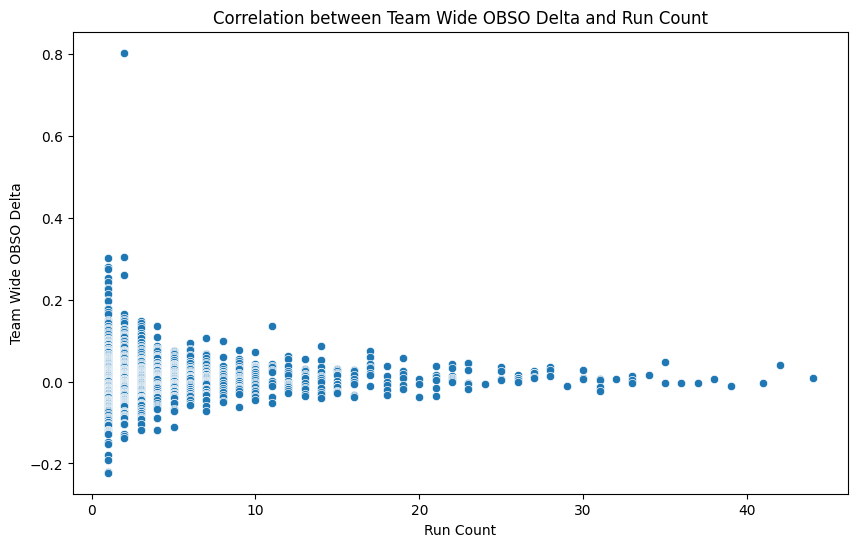

In [173]:
# plot corr between team_wide_OBSO_delta and run_count
plt.figure(figsize=(10, 6))
sns.scatterplot(data=grouped_df, x='run_count', y='team_wide_OBSO_delta')
plt.title('Correlation between Team Wide OBSO Delta and Run Count')
plt.xlabel('Run Count')
plt.ylabel('Team Wide OBSO Delta')
plt.show()

## Get the OBSO delta by Runner

In [177]:
# Make DF of OBSO metrics
obso_metrics_runner = []

for run in runs:
    

    
    # Get runner metrics
    runner_metrics = {
        'match_id': run['match_id'],
        'run_id': run['run_id'],
        'team_id': run['team_id'],
        'player_id': run['player_id'],
        'start_frame': run['start_frame'],
        'end_frame': run['end_frame'],
        'period': run['period'],
        'is_runner': True,
        'OBSO_delta' : run['runner_info']['metrics']['OBSO_delta']

    }
    obso_metrics_runner.append(runner_metrics)
    
# Convert to DataFrame
obso_runner_df = pd.DataFrame(obso_metrics_runner)
obso_runner_df

,match_id,run_id,team_id,player_id,start_frame,end_frame,period,is_runner,OBSO_delta
0,622555,622555_14,12,1248525,648,676,1,True,0.006111
1,622555,622555_15,12,1281301,668,686,1,True,-0.026609
2,622555,622555_17,12,1304950,744,760,1,True,0.014945
3,622555,622555_39,12,1733126,3452,3466,1,True,-0.016101
4,622555,622555_41,12,1732978,3462,3486,1,True,0.025237
...,...,...,...,...,...,...,...,...,...
6556,666385,666385_404,3651,1329659,51920,51962,2,True,-0.005443
6557,666385,666385_432,3651,69700,54954,54968,2,True,-0.008195
6558,666385,666385_436,3659,1322737,55386,55406,2,True,0.012872
6559,666385,666385_437,3659,1159149,55388,55408,2,True,-0.014522


In [179]:
# Grouping by 'player_id' and summing 'team_wide_OBSO_delta'
grouped_df_runner = obso_runner_df.groupby('player_id')['OBSO_delta'].sum().reset_index()

# Sort by team_wide_OBSO_delta
grouped_df_runner = grouped_df_runner.sort_values(by='OBSO_delta', ascending=False)


# Join with t_player_data
t_player_data = pd.read_csv("/Users/svasquez/AWS_PC/t_player_data.csv")

grouped_df_runner = grouped_df_runner.merge(t_player_data, on='player_id', how='left')

# Merge with run counts

grouped_df_runner = grouped_df_runner.merge(run_counts, on='player_id', how='left')

# get onoy playes that have at least 10 runs
grouped_df_runner = grouped_df_runner[grouped_df_runner['run_count'] >= 10]

grouped_df_runner.head(20)

,player_id,OBSO_delta,name_x,team_id_x,run_count,name_y,team_id_y
1,1242415,0.296074,Jan Paul Van Hecke,2019,12,Jan Paul Van Hecke,2019
2,41349,0.257204,Dan Burn,1932,17,Dan Burn,1932
3,1301778,0.255186,Levi Colwill,1930,14,Levi Colwill,1930
5,1155313,0.226165,Christopher Nkunku,1930,22,Christopher Nkunku,1930
6,1157172,0.215298,Alexander Isak,1932,22,Alexander Isak,1932
8,240037,0.198506,Fabian Schar,1932,15,Fabian Schar,1932
19,1295026,0.133448,Martinelli,1928,35,Martinelli,1928
20,138606,0.130819,Bernardo Silva,1939,30,Bernardo Silva,1939
21,1158367,0.121711,Aaron Wan Bissaka,1948,10,Aaron Wan Bissaka,1948
22,1619221,0.119149,Kobbie Mainoo,1946,13,Kobbie Mainoo,1946
